# KeraMine — Notebook 02: Eksplorasi SOTA Association Rules, Utility-QTY, Uji Fisher-BH & Evaluasi Temporal
**Proyek UAS Analisis Data Mining (ADAMIN)** | **Input:** `transactions_clean.csv` (hasil Colab Notebook 01)

Notebook ini dijalankan di **Google Colab** (`Runtime -> Run all`) dan melakukan:
1. **Inisialisasi, Filter Warning (`StderrFilter`) & Muat Data Bersih** (`15.840` transaksi pembelian positif dari `adamin_colab_01_outputs.zip` atau `transactions_clean.csv`).
2. **Benchmark 3 Algoritma SOTA Frequent Itemset Mining:**
   - Membandingkan **Apriori** (baseline), **FP-Growth** (tree-based cepat), dan **FP-Max** (*Maximal Frequent Itemsets* untuk pemangkasan redundansi) pada 5 level hierarki item (`MERK`, `UKURAN`, `MERK_UKURAN`, `SERI`, `NAMABARA`).
   - Memverifikasi kesamaan hasil *frequent itemsets* antara Apriori dan FP-Growth (`assert`).
3. **Ekstraksi Aturan Multi-Level + Metrik SOTA + Utility-QTY + Uji Statistik Fisher-BH:**
   - Menghitung metrik klasik (*Support, Confidence, Lift*) dan SOTA (*Leverage, Conviction, Kulczynski*, **Zhang's Metric**).
   - Menghitung bobot volume fisik kardus (`QTY`) menjadi **`utility_score`**.
   - Menjalankan **Fisher's Exact Test** pada tabel kontingensi $2\times 2$ + koreksi *False Discovery Rate* **Benjamini-Hochberg (`q_value_bh`)** untuk menyaring aturan kebetulan.
4. **Evaluasi Prediktif Temporal (*Out-of-Time Validation*):**
   - Memisahkan *Train* (`2022-08` s.d. `2023-09`, 14 bulan) dan *Test* (`2023-10` s.d. `2023-12`, 3 bulan) untuk mengukur **Hit-Rate@5**, **Precision@5**, dan **Coverage** antara ARM Murni vs Hybrid (ARM + Popularity Fallback) vs Baseline Popularitas.
5. **Pengemasan Artefak & Kontrak Uji (`adamin_colab_02_outputs.zip`):**
   - Menghasilkan `mined_rules_catalog.csv`, `sota_benchmark_summary.json`, `temporal_eval_report.json`, `arm_fixture.json`, serta 2 grafik visualisasi untuk Laporan UAS & aplikasi FastAPI/Laravel/Streamlit.

In [3]:
# ==============================================================================
# CELL 1: Setup Lingkungan, StderrFilter & Muat transactions_clean.csv
# ==============================================================================
import warnings
warnings.filterwarnings("ignore")

import sys

class StderrFilter:
    def __init__(self, original):
        self.original = original
    def write(self, text):
        if "jupyter_client" not in text and "DeprecationWarning" not in text and "utcnow" not in text:
            self.original.write(text)
    def flush(self):
        self.original.flush()

sys.stderr = StderrFilter(sys.stderr)

import os
import time
import json
import math
import hashlib
import zipfile
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import fisher_exact

# Pastikan mlxtend & scipy tersedia
try:
    from mlxtend.preprocessing import TransactionEncoder
    from mlxtend.frequent_patterns import apriori, fpgrowth, fpmax, association_rules
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "mlxtend>=0.23.0"])
    from mlxtend.preprocessing import TransactionEncoder
    from mlxtend.frequent_patterns import apriori, fpgrowth, fpmax, association_rules

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

IN_COLAB = "google.colab" in sys.modules
OUT_DIR = "adamin_colab_02_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# Cari transactions_clean.csv atau ekstrak dari adamin_colab_01_outputs.zip
candidate_csv = [
    "transactions_clean.csv",
    "adamin_colab_01_outputs/transactions_clean.csv",
    "../data/clean/transactions_clean.csv",
    "data/clean/transactions_clean.csv",
    "/content/transactions_clean.csv",
    "/content/adamin_colab_01_outputs/transactions_clean.csv",
]
csv_path = next((p for p in candidate_csv if os.path.exists(p)), None)

if csv_path is None:
    candidate_zip = [
        "adamin_colab_01_outputs.zip",
        "/content/adamin_colab_01_outputs.zip",
        "notebooks/adamin_colab_01_outputs.zip",
    ]
    zip01 = next((p for p in candidate_zip if os.path.exists(p)), None)
    if zip01:
        with zipfile.ZipFile(zip01, "r") as zf:
            zf.extractall("adamin_colab_01_outputs")
        csv_path = "adamin_colab_01_outputs/transactions_clean.csv"

if csv_path is None and IN_COLAB:
    from google.colab import files
    print("Silakan unggah adamin_colab_01_outputs.zip atau transactions_clean.csv...")
    uploaded = files.upload()
    for fname in uploaded.keys():
        if fname.lower().endswith(".zip"):
            with zipfile.ZipFile(fname, "r") as zf:
                zf.extractall("adamin_colab_01_outputs")
            csv_path = "adamin_colab_01_outputs/transactions_clean.csv"
            break
        elif fname.lower().endswith(".csv"):
            csv_path = fname
            break

assert csv_path is not None and os.path.exists(csv_path), (
    "transactions_clean.csv tidak ditemukan! Unggah hasil Notebook 01 terlebih dahulu."
)

df = pd.read_csv(csv_path)
df["basket_store_month"] = df["nama_toko"] + "|" + df["year_month"]
df["basket_store_week"] = df["nama_toko"] + "|" + df["year_week"]

assert len(df) == 15840, f"Ekspektasi 15.840 baris bersih, terbaca {len(df)}"
assert df["basket_store_month"].nunique() == 3949

print(f"Data bersih dimuat dari: {csv_path}")
print(f"Total transaksi positif : {len(df):,} baris | Total DUS: {int(df['qty'].sum()):,}")
print(f"Keranjang Toko+Bulan    : {df['basket_store_month'].nunique():,}")
print(f"Keranjang Toko+Minggu   : {df['basket_store_week'].nunique():,}")

Data bersih dimuat dari: transactions_clean.csv
Total transaksi positif : 15,840 baris | Total DUS: 794,064
Keranjang Toko+Bulan    : 3,949
Keranjang Toko+Minggu   : 10,475


## 2. Benchmark Komputasi 3 Algoritma SOTA (Apriori vs FP-Growth vs FP-Max)
Pada sel ini kita membandingkan tiga algoritma penambangan *frequent itemsets* pada keranjang utama `Toko + Bulan` (`3.949` keranjang):
* **Apriori:** Pencarian berbasis pembangkitan kandidat *level-wise*.
* **FP-Growth:** Pencarian berbasis pohon prefiks terkompresi (*FP-Tree*) tanpa pembangkitan kandidat.
* **FP-Max:** Ekstraksi hanya *Maximal Frequent Itemsets* guna memangkas subset itemset yang redundan.

=== BENCHMARK ALGORITMA SOTA (TOKO + BULAN, 3.949 KERANJANG) ===


,item_level,unique_items,min_support,apriori_ms,fpgrowth_ms,fpmax_ms,speedup_fp_vs_apriori,itemsets_apriori_fp,itemsets_fpmax,fpmax_pruning_pct
0,MERK,21,0.0200,45.47,5108.98,2685.72,0.01,231,210,9.09
1,UKURAN,8,0.0200,4.12,417.47,125.77,0.01,41,9,78.05
2,MERK_UKURAN,168,0.0020,93.27,20725.28,18999.11,0.00,1603,1519,5.24
3,SERI,220,0.0015,41.40,8997.88,6741.14,0.00,746,602,19.30
4,NAMABARA,438,0.0010,56.11,1055.25,1122.43,0.05,474,409,13.71


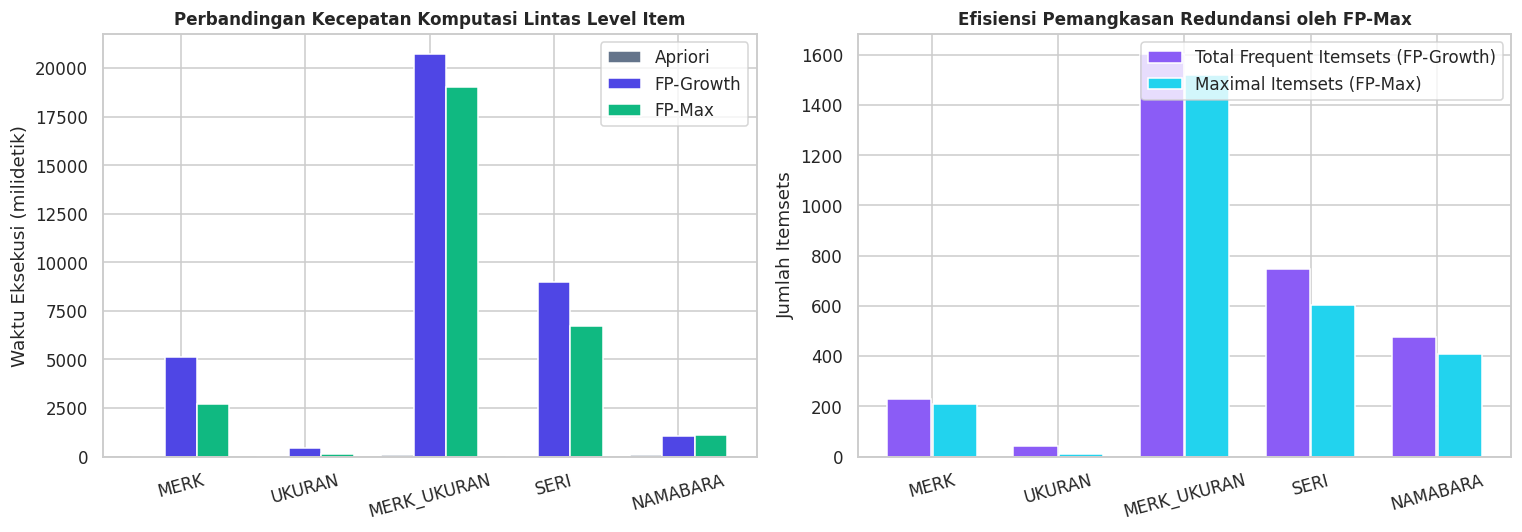

In [4]:
# ==============================================================================
# CELL 2: Benchmark Waktu Komputasi & Efisiensi Redundansi (Apriori vs FP-Growth vs FP-Max)
# ==============================================================================
def build_onehot_matrix(df_in: pd.DataFrame, basket_col: str, item_col: str):
    grouped = df_in.groupby(basket_col)[item_col].apply(lambda s: sorted(set(s.astype(str))))
    basket_ids = grouped.index.tolist()
    transactions = grouped.tolist()
    te = TransactionEncoder()
    arr = te.fit(transactions).transform(transactions)
    onehot = pd.DataFrame(arr, index=basket_ids, columns=te.columns_)
    return onehot, transactions

# Konfigurasi terkalibrasi untuk benchmark lintas-level pada Toko + Bulan
BENCHMARK_CONFIGS = [
    {"item_level": "MERK", "col": "merk_clean", "min_support": 0.0200},
    {"item_level": "UKURAN", "col": "ukuran", "min_support": 0.0200},
    {"item_level": "MERK_UKURAN", "col": "merk_ukuran", "min_support": 0.0020},
    {"item_level": "SERI", "col": "seri", "min_support": 0.0015},
    {"item_level": "NAMABARA", "col": "namabara", "min_support": 0.0010},
]

benchmark_rows = []
onehot_cache = {}

for cfg in BENCHMARK_CONFIGS:
    lv = cfg["item_level"]
    col = cfg["col"]
    ms = cfg["min_support"]

    onehot, _ = build_onehot_matrix(df, "basket_store_month", col)
    onehot_cache[("store_month", lv)] = onehot

    # 1. Apriori (untuk level sangat sparse/438 kolom tetap aman di 3.949 baris; batas max_len=3)
    t0 = time.perf_counter()
    fi_ap = apriori(onehot, min_support=ms, use_colnames=True, max_len=3, low_memory=(onehot.shape[1] > 100))
    ap_ms = (time.perf_counter() - t0) * 1000.0

    # 2. FP-Growth
    t0 = time.perf_counter()
    fi_fp = fpgrowth(onehot, min_support=ms, use_colnames=True, max_len=3)
    fp_ms = (time.perf_counter() - t0) * 1000.0

    # 3. FP-Max (Maximal Frequent Itemsets)
    t0 = time.perf_counter()
    fi_max = fpmax(onehot, min_support=ms, use_colnames=True, max_len=3)
    fm_ms = (time.perf_counter() - t0) * 1000.0

    # Verifikasi paritas himpunan itemsets antara Apriori dan FP-Growth
    set_ap = {frozenset(x) for x in fi_ap["itemsets"]}
    set_fp = {frozenset(x) for x in fi_fp["itemsets"]}
    assert set_ap == set_fp, f"Mismatch Apriori vs FP-Growth pada level {lv}!"

    reduction_pct = (1.0 - (len(fi_max) / len(fi_fp))) * 100.0 if len(fi_fp) > 0 else 0.0
    speedup = ap_ms / fp_ms if fp_ms > 0 else 1.0

    benchmark_rows.append({
        "item_level": lv,
        "unique_items": int(onehot.shape[1]),
        "min_support": ms,
        "apriori_ms": round(ap_ms, 2),
        "fpgrowth_ms": round(fp_ms, 2),
        "fpmax_ms": round(fm_ms, 2),
        "speedup_fp_vs_apriori": round(speedup, 2),
        "itemsets_apriori_fp": int(len(fi_fp)),
        "itemsets_fpmax": int(len(fi_max)),
        "fpmax_pruning_pct": round(reduction_pct, 2),
    })

df_bench = pd.DataFrame(benchmark_rows)
print("=== BENCHMARK ALGORITMA SOTA (TOKO + BULAN, 3.949 KERANJANG) ===")
try:
    display(df_bench)
except NameError:
    print(df_bench)

# Visualisasi Benchmark Waktu Eksekusi & Reduksi Itemset FP-Max
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(df_bench))
w = 0.26

axes[0].bar(x - w, df_bench["apriori_ms"], width=w, label="Apriori", color="#64748B")
axes[0].bar(x, df_bench["fpgrowth_ms"], width=w, label="FP-Growth", color="#4F46E5")
axes[0].bar(x + w, df_bench["fpmax_ms"], width=w, label="FP-Max", color="#10B981")
axes[0].set_xticks(x)
axes[0].set_xticklabels(df_bench["item_level"], rotation=15)
axes[0].set_ylabel("Waktu Eksekusi (milidetik)")
axes[0].set_title("Perbandingan Kecepatan Komputasi Lintas Level Item", fontsize=11, fontweight="bold")
axes[0].legend()

axes[1].bar(x - 0.18, df_bench["itemsets_apriori_fp"], width=0.35, label="Total Frequent Itemsets (FP-Growth)", color="#8B5CF6")
axes[1].bar(x + 0.18, df_bench["itemsets_fpmax"], width=0.35, label="Maximal Itemsets (FP-Max)", color="#22D3EE")
axes[1].set_xticks(x)
axes[1].set_xticklabels(df_bench["item_level"], rotation=15)
axes[1].set_ylabel("Jumlah Itemsets")
axes[1].set_title("Efisiensi Pemangkasan Redundansi oleh FP-Max", fontsize=11, fontweight="bold")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "sota_algorithm_benchmark.png"), bbox_inches="tight")
plt.show()

## 3. Mesin SOTA Association Rules: Zhang's Metric, Utility-QTY & Uji Statistik Fisher-BH
Pada tahap ini kita mengekstrak seluruh aturan asosiasi untuk unit keranjang **`store_month`** (`Toko + Bulan`) dan **`store_week`** (`Toko + Minggu`) di seluruh 5 level item, lengkap dengan:
* **Metrik Klasik:** `support`, `confidence`, `lift`.
* **Metrik SOTA:** `leverage`, `conviction`, `kulczynski`, **`zhang_metric`** ($-1$ s.d. $+1$).
* **Pembobotan Kuantitas Fisik (`QTY`):** `total_qty_dus`, `avg_qty_dus`, dan `utility_score` $= \text{confidence} \times \max(0, \text{zhang\_metric}) \times \log_{10}(1 + \bar{Q}_{AC})$.
* **Penyaringan Signifikansi Statistik:** `p_value_fisher` (*Fisher's Exact Test* satu-sisi pada tabel $2\times 2$) dan `q_value_bh` (*Benjamini-Hochberg FDR*).

=== RINGKASAN EKSTRAKSI RULES & UJI STATISTIK FISHER-BH ===


,basket_type,item_level,min_support,min_confidence,total_baskets,rules_found,fisher_p_lt_005,fdr_bh_q_lt_010,max_lift,max_zhang,exec_time_ms
0,store_month,MERK,0.0200,0.15,3949,349,14,0,1.197,0.198,2933.82
1,store_month,UKURAN,0.0200,0.20,3949,84,2,0,1.109,0.106,492.97
2,store_month,MERK_UKURAN,0.0020,0.10,3949,127,34,27,2.790,0.660,20096.40
3,store_month,SERI,0.0015,0.10,3949,104,61,72,5.683,0.838,7529.69
4,store_month,NAMABARA,0.0010,0.10,3949,39,39,39,16.118,0.946,629.05
5,store_week,MERK,0.0020,0.05,10475,57,0,0,0.970,-0.032,8397.82
6,store_week,MERK_UKURAN,0.0004,0.05,10475,6,2,1,2.951,0.667,7025.87
7,store_week,SERI,0.0003,0.05,10475,18,14,15,16.627,0.946,2465.47



=== TOP 12 ATURAN LEVEL UTAMA (SERI - TOKO+BULAN) BERDASARKAN UTILITY & ZHANG ===


,antecedents_str,consequents_str,n_ab,support,confidence,lift,zhang_metric,avg_qty_dus,utility_score,p_value_fisher,q_value_bh
625,DIEGO,GRANIT,11,0.002786,0.166667,3.964859,0.760494,96.090909,0.251873,0.000075,0.007551
610,SENGGIGI,AMARILIS,7,0.001773,0.109375,5.683183,0.837617,113.285714,0.188542,0.000191,0.007551
573,ELECTRA,ILUSION,9,0.002279,0.103448,4.255388,0.782237,105.555556,0.164074,0.000218,0.007551
639,FOSSIL,ELYSIUM,7,0.001773,0.114754,4.531639,0.791556,111.857143,0.186440,0.000769,0.019999
660,HITAM,FINO,6,0.001519,0.153846,5.020979,0.808824,106.500000,0.252777,0.001041,0.021657
617,SOLIKI,PEDRA,7,0.001773,0.118644,4.039012,0.763827,99.000000,0.181247,0.001516,0.024129
654,PULSAR,GRANITY,8,0.002026,0.186047,3.433167,0.716526,94.250000,0.263797,0.001823,0.024129
659,CUBIC,MIRANDA,6,0.001519,0.193548,4.443736,0.781096,111.666667,0.310190,0.001856,0.024129
560,KRUING,EMERALD,10,0.002532,0.103093,2.866996,0.667601,113.100000,0.141592,0.002273,0.024482
643,EMPERADOR,ILUSION,6,0.001519,0.105263,4.330044,0.780319,108.500000,0.167515,0.002354,0.024482


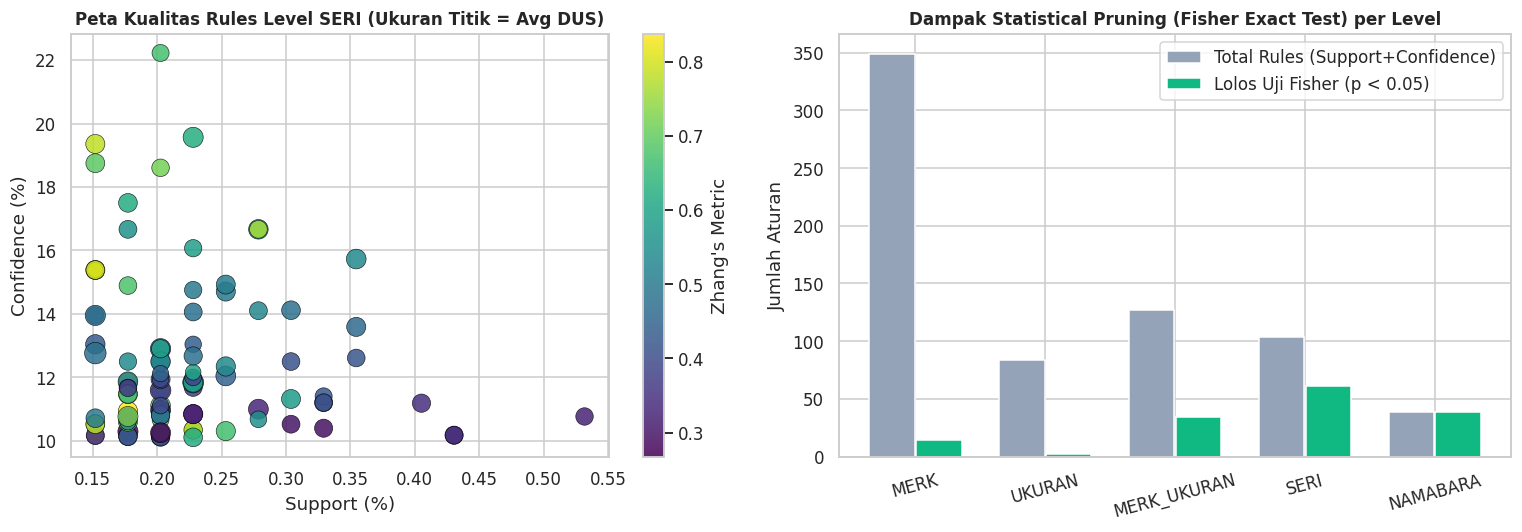

In [5]:
# ==============================================================================
# CELL 3: Ekstraksi Rules Lintas Level & Perhitungan Metrik SOTA + Fisher-BH
# ==============================================================================
def benjamini_hochberg(p_values: np.ndarray) -> np.ndarray:
    m = len(p_values)
    if m == 0:
        return np.array([], dtype=float)
    order = np.argsort(p_values)
    sorted_p = p_values[order]
    ranks = np.arange(1, m + 1, dtype=float)
    q_sorted = sorted_p * m / ranks
    q_sorted = np.minimum.accumulate(q_sorted[::-1])[::-1]
    q_sorted = np.clip(q_sorted, 0.0, 1.0)
    q_vals = np.empty(m, dtype=float)
    q_vals[order] = q_sorted
    return q_vals

def make_rule_id(basket_type: str, item_level: str, ant_list: list, con_list: list) -> str:
    payload = f"{basket_type}|{item_level}|{' + '.join(ant_list)}->{' + '.join(con_list)}"
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()[:32]

def mine_sota_rules_for_level(
    df_in: pd.DataFrame,
    basket_type: str,
    basket_col: str,
    item_level: str,
    item_col: str,
    min_support: float,
    min_confidence: float,
    onehot: pd.DataFrame = None,
) -> tuple:
    t0 = time.perf_counter()
    if onehot is None:
        onehot, _ = build_onehot_matrix(df_in, basket_col, item_col)

    N = len(onehot)
    fi = fpgrowth(onehot, min_support=min_support, use_colnames=True, max_len=3)
    if fi.empty or (fi["itemsets"].apply(len) >= 2).sum() == 0:
        return pd.DataFrame(), (time.perf_counter() - t0) * 1000.0, N

    rules_df = association_rules(fi, metric="confidence", min_threshold=min_confidence)
    if rules_df.empty:
        return pd.DataFrame(), (time.perf_counter() - t0) * 1000.0, N

    # Siapkan peta QTY per (basket_id, item) untuk perhitungan Utility-QTY cepat
    qty_per_basket_item = (
        df_in.assign(_item_str=df_in[item_col].astype(str)).groupby([basket_col, "_item_str"])["qty"]
        .sum()
        .unstack(fill_value=0.0)
        .reindex(index=onehot.index, columns=onehot.columns, fill_value=0.0)
    )
    onehot_np = onehot.to_numpy(dtype=bool)
    qty_np = qty_per_basket_item.to_numpy(dtype=float)
    col_to_idx = {col: idx for idx, col in enumerate(onehot.columns)}

    enriched_rows = []
    for _, row in rules_df.iterrows():
        ant = sorted(list(row["antecedents"]))
        con = sorted(list(row["consequents"]))
        union_items = ant + con

        ant_idx = [col_to_idx[x] for x in ant]
        con_idx = [col_to_idx[x] for x in con]
        union_idx = ant_idx + con_idx

        has_a = onehot_np[:, ant_idx].all(axis=1)
        has_b = onehot_np[:, con_idx].all(axis=1)
        has_ab = has_a & has_b

        n_a = int(has_a.sum())
        n_b = int(has_b.sum())
        n_ab = int(has_ab.sum())

        p_a = n_a / N
        p_b = n_b / N
        p_ab = n_ab / N

        supp = p_ab
        conf = n_ab / n_a if n_a > 0 else 0.0
        lift = conf / p_b if p_b > 0 else 0.0
        lev = p_ab - (p_a * p_b)
        conv = (1.0 - p_b) / (1.0 - conf) if conf < 1.0 else 999.0
        kulc = 0.5 * ((n_ab / n_a if n_a > 0 else 0.0) + (n_ab / n_b if n_b > 0 else 0.0))

        denom_z = max(p_ab * (1.0 - p_a), p_a * (p_b - p_ab))
        zhang = (p_ab - p_a * p_b) / denom_z if denom_z > 0 else 0.0

        # Volume Utility berbasis kolom QTY (DUS)
        ab_qty_per_basket = qty_np[has_ab][:, union_idx].sum(axis=1) if n_ab > 0 else np.array([0.0])
        total_qty_dus = float(ab_qty_per_basket.sum())
        avg_qty_dus = float(ab_qty_per_basket.mean()) if n_ab > 0 else 0.0
        utility_score = conf * max(0.0, zhang) * math.log10(1.0 + avg_qty_dus)

        # Fisher's Exact Test 2x2 satu-sisi ('greater')
        n11 = n_ab
        n10 = n_a - n_ab
        n01 = n_b - n_ab
        n00 = N - n_a - n_b + n_ab
        _, p_val = fisher_exact([[n11, n10], [n01, n00]], alternative="greater")

        ant_str = " + ".join(ant)
        con_str = " + ".join(con)

        enriched_rows.append({
            "id": make_rule_id(basket_type, item_level, ant, con),
            "basket_type": basket_type,
            "item_level": item_level,
            "antecedents": json.dumps(ant),
            "consequents": json.dumps(con),
            "antecedents_str": ant_str,
            "consequents_str": con_str,
            "n_a": n_a,
            "n_b": n_b,
            "n_ab": n_ab,
            "total_baskets": N,
            "support": supp,
            "confidence": conf,
            "lift": lift,
            "leverage": lev,
            "conviction": conv,
            "kulczynski": kulc,
            "zhang_metric": zhang,
            "total_qty_dus": total_qty_dus,
            "avg_qty_dus": avg_qty_dus,
            "utility_score": utility_score,
            "p_value_fisher": float(p_val),
        })

    out_df = pd.DataFrame(enriched_rows)
    out_df["q_value_bh"] = benjamini_hochberg(out_df["p_value_fisher"].to_numpy())
    out_df["is_significant"] = out_df["p_value_fisher"] < 0.05
    out_df["is_fdr_significant"] = out_df["q_value_bh"] < 0.10
    elapsed_ms = (time.perf_counter() - t0) * 1000.0
    return out_df, elapsed_ms, N

MINING_PLAN = [
    ("store_month", "basket_store_month", "MERK", "merk_clean", 0.0200, 0.15),
    ("store_month", "basket_store_month", "UKURAN", "ukuran", 0.0200, 0.20),
    ("store_month", "basket_store_month", "MERK_UKURAN", "merk_ukuran", 0.0020, 0.10),
    ("store_month", "basket_store_month", "SERI", "seri", 0.0015, 0.10),
    ("store_month", "basket_store_month", "NAMABARA", "namabara", 0.0010, 0.10),
    ("store_week",  "basket_store_week",  "MERK", "merk_clean", 0.0020, 0.05),
    ("store_week",  "basket_store_week",  "MERK_UKURAN", "merk_ukuran", 0.0004, 0.05),
    ("store_week",  "basket_store_week",  "SERI", "seri", 0.0003, 0.05),
]

all_rule_dfs = []
run_summaries = []

for btype, bcol, lv, icol, msup, mconf in MINING_PLAN:
    cached = onehot_cache.get((btype, lv))
    rdf, ms_time, nbask = mine_sota_rules_for_level(df, btype, bcol, lv, icol, msup, mconf, cached)
    if not rdf.empty:
        all_rule_dfs.append(rdf)
        sig_p = int(rdf["is_significant"].sum())
        sig_q = int(rdf["is_fdr_significant"].sum())
        top_lift = round(float(rdf["lift"].max()), 3)
        top_zhang = round(float(rdf["zhang_metric"].max()), 3)
    else:
        sig_p = sig_q = 0
        top_lift = top_zhang = 0.0

    run_summaries.append({
        "basket_type": btype,
        "item_level": lv,
        "min_support": msup,
        "min_confidence": mconf,
        "total_baskets": nbask,
        "rules_found": int(len(rdf)),
        "fisher_p_lt_005": sig_p,
        "fdr_bh_q_lt_010": sig_q,
        "max_lift": top_lift,
        "max_zhang": top_zhang,
        "exec_time_ms": round(ms_time, 2),
    })

df_rules_all = pd.concat(all_rule_dfs, ignore_index=True)
df_run_summary = pd.DataFrame(run_summaries)

print("=== RINGKASAN EKSTRAKSI RULES & UJI STATISTIK FISHER-BH ===")
try:
    display(df_run_summary)
except NameError:
    print(df_run_summary)

print("\n=== TOP 12 ATURAN LEVEL UTAMA (SERI - TOKO+BULAN) BERDASARKAN UTILITY & ZHANG ===")
seri_top = (
    df_rules_all[(df_rules_all["basket_type"] == "store_month") & (df_rules_all["item_level"] == "SERI")]
    .sort_values(by=["p_value_fisher", "utility_score"], ascending=[True, False])
    .head(12)
)
cols_show = ["antecedents_str", "consequents_str", "n_ab", "support", "confidence", "lift", "zhang_metric", "avg_qty_dus", "utility_score", "p_value_fisher", "q_value_bh"]
try:
    display(seri_top[cols_show])
except NameError:
    print(seri_top[cols_show])

# Visualisasi Scatter SOTA: Support vs Confidence, warna = Zhang's Metric, ukuran = Avg DUS
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
seri_df = df_rules_all[(df_rules_all["basket_type"] == "store_month") & (df_rules_all["item_level"] == "SERI")]

sc = axes[0].scatter(
    seri_df["support"] * 100,
    seri_df["confidence"] * 100,
    c=seri_df["zhang_metric"],
    s=np.clip(seri_df["avg_qty_dus"] * 1.4, 25, 350),
    cmap="viridis",
    alpha=0.85,
    edgecolors="black",
    linewidth=0.4,
)
plt.colorbar(sc, ax=axes[0], label="Zhang's Metric")
axes[0].set_xlabel("Support (%)")
axes[0].set_ylabel("Confidence (%)")
axes[0].set_title("Peta Kualitas Rules Level SERI (Ukuran Titik = Avg DUS)", fontsize=11, fontweight="bold")

# Panel 2: Perbandingan rules sebelum vs sesudah Fisher p < 0.05
sm_sum = df_run_summary[df_run_summary["basket_type"] == "store_month"]
x2 = np.arange(len(sm_sum))
axes[1].bar(x2 - 0.18, sm_sum["rules_found"], width=0.35, label="Total Rules (Support+Confidence)", color="#94A3B8")
axes[1].bar(x2 + 0.18, sm_sum["fisher_p_lt_005"], width=0.35, label="Lolos Uji Fisher (p < 0.05)", color="#10B981")
axes[1].set_xticks(x2)
axes[1].set_xticklabels(sm_sum["item_level"], rotation=15)
axes[1].set_ylabel("Jumlah Aturan")
axes[1].set_title("Dampak Statistical Pruning (Fisher Exact Test) per Level", fontsize=11, fontweight="bold")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "sota_rules_metrics_scatter.png"), bbox_inches="tight")
plt.show()

## 4. Evaluasi Prediktif Temporal (*Out-of-Time Validation*: Agu 2022–Sep 2023 vs Okt–Des 2023)
Menguji kemampuan sistem rekomendasi memprediksi keranjang pesanan *restocking* nyata di masa depan (**3 bulan terakhir: `2023-10` s.d. `2023-12`**) berdasarkan aturan yang ditambang dari **14 bulan sebelumnya (`2022-08` s.d. `2023-09`)**. Kita membandingkan 3 strategi:
1. **ARM Murni:** Hanya memberi rekomendasi jika item pemicu memiliki aturan asosiasi dari data latih.
2. **Baseline Popularitas Global:** Selalu merekomendasikan Top-$K$ item paling populer di data latih.
3. **Hybrid KeraMine (ARM + Popularity Fallback):** Memprioritaskan rekomendasi aturan asosiasi (urut `utility_score`), lalu melengkapinya hingga $K$ item dengan *Volume Popularity Fallback* bila masih tersisa slot.

In [6]:
# ==============================================================================
# CELL 4: Evaluasi Temporal Train (2022-08..2023-09) vs Test (2023-10..2023-12)
# ==============================================================================
TRAIN_CUTOFF = "2023-09"
df_train = df[df["year_month"] <= TRAIN_CUTOFF].copy()
df_test = df[df["year_month"] > TRAIN_CUTOFF].copy()

def evaluate_temporal_hit_rate(item_col: str, item_level: str, min_sup: float, min_conf: float, top_k: int = 5):
    train_rules, _, n_train_b = mine_sota_rules_for_level(
        df_train, "store_month", "basket_store_month", item_level, item_col, min_sup, min_conf
    )
    # Peta popularitas volume DUS di data latih
    pop_ranked = (
        df_train.groupby(item_col)["qty"]
        .sum()
        .sort_values(ascending=False)
        .index.tolist()
    )

    # Peta lookup aturan: 1-item antecedent -> daftar consequent terurut utility_score DESC
    rule_map = {}
    if not train_rules.empty:
        single_ant = train_rules[train_rules["antecedents"].apply(lambda s: len(json.loads(s)) == 1)].copy()
        single_ant = single_ant.sort_values(by=["is_significant", "utility_score", "lift"], ascending=[False, False, False])
        for _, r in single_ant.iterrows():
            a = json.loads(r["antecedents"])[0]
            cs = json.loads(r["consequents"])
            rule_map.setdefault(a, [])
            for c in cs:
                if c not in rule_map[a]:
                    rule_map[a].append(c)

    test_baskets = df_test.groupby("basket_store_month")[item_col].apply(lambda s: sorted(set(s))).tolist()
    # Uji pada keranjang uji yang memiliki >= 2 item (1 item pertama sebagai pemicu/query, sisanya sebagai ground truth)
    multi_test = [b for b in test_baskets if len(b) >= 2]

    hits_arm, hits_pop, hits_hybrid = 0, 0, 0
    prec_arm, prec_pop, prec_hybrid = [], [], []
    arm_covered = 0

    for b in multi_test:
        # Gunakan item terpopuler kedua atau pertama secara deterministik (b[0]) sebagai trigger di kasir/sales
        trigger = b[0]
        truth = set(b[1:])

        rec_arm = [x for x in rule_map.get(trigger, []) if x != trigger][:top_k]
        if rec_arm:
            arm_covered += 1

        rec_pop = [x for x in pop_ranked if x != trigger][:top_k]

        rec_hybrid = list(rec_arm)
        for p_item in pop_ranked:
            if p_item != trigger and p_item not in rec_hybrid:
                rec_hybrid.append(p_item)
            if len(rec_hybrid) >= top_k:
                break

        h_a = len(set(rec_arm) & truth)
        h_p = len(set(rec_pop) & truth)
        h_h = len(set(rec_hybrid) & truth)

        hits_arm += int(h_a > 0)
        hits_pop += int(h_p > 0)
        hits_hybrid += int(h_h > 0)

        prec_arm.append(h_a / top_k)
        prec_pop.append(h_p / top_k)
        prec_hybrid.append(h_h / top_k)

    total_q = len(multi_test)
    return {
        "item_level": item_level,
        "train_baskets": int(n_train_b),
        "test_multi_baskets": int(total_q),
        "train_rules_count": int(len(train_rules)),
        "arm_coverage_pct": round(arm_covered * 100.0 / total_q, 2) if total_q else 0.0,
        "hit_rate_at_5_arm_only_pct": round(hits_arm * 100.0 / total_q, 2) if total_q else 0.0,
        "hit_rate_at_5_popularity_pct": round(hits_pop * 100.0 / total_q, 2) if total_q else 0.0,
        "hit_rate_at_5_hybrid_pct": round(hits_hybrid * 100.0 / total_q, 2) if total_q else 0.0,
        "precision_at_5_arm_pct": round(float(np.mean(prec_arm)) * 100.0, 2) if prec_arm else 0.0,
        "precision_at_5_popularity_pct": round(float(np.mean(prec_pop)) * 100.0, 2) if prec_pop else 0.0,
        "precision_at_5_hybrid_pct": round(float(np.mean(prec_hybrid)) * 100.0, 2) if prec_hybrid else 0.0,
    }

eval_results = [
    evaluate_temporal_hit_rate("merk_clean", "MERK", 0.0200, 0.15, top_k=5),
    evaluate_temporal_hit_rate("merk_ukuran", "MERK_UKURAN", 0.0020, 0.10, top_k=5),
    evaluate_temporal_hit_rate("seri", "SERI", 0.0015, 0.10, top_k=5),
]
df_eval = pd.DataFrame(eval_results)
print(f"=== EVALUASI OUT-OF-TIME (Train <= {TRAIN_CUTOFF}: {len(df_train):,} tx | Test > {TRAIN_CUTOFF}: {len(df_test):,} tx) ===")
try:
    display(df_eval)
except NameError:
    print(df_eval)

=== EVALUASI OUT-OF-TIME (Train <= 2023-09: 13,082 tx | Test > 2023-09: 2,758 tx) ===


,item_level,train_baskets,test_multi_baskets,train_rules_count,arm_coverage_pct,hit_rate_at_5_arm_only_pct,hit_rate_at_5_popularity_pct,hit_rate_at_5_hybrid_pct,precision_at_5_arm_pct,precision_at_5_popularity_pct,precision_at_5_hybrid_pct
0,MERK,3255,634,347,100.00,53.63,63.25,66.25,14.16,17.03,19.94
1,MERK_UKURAN,3255,638,154,80.25,11.76,30.09,31.50,2.51,6.80,7.12
2,SERI,3255,636,143,44.03,3.14,19.18,18.71,0.63,4.12,3.99


## 5. Ekspor Kontrak Uji (`arm_fixture.json`) & Pengemasan Otomatis `adamin_colab_02_outputs.zip`
Seluruh hasil penambangan dan benchmark dikemas agar dapat langsung digunakan untuk:
* Seeding ke tabel `keramine_rules` dan `keramine_mining_runs` di **Supabase**.
* Unit test kontrak paritas numerik ($\le 10^{-6}$) pada layanan **FastAPI** (`api-engine/`).

In [7]:
# ==============================================================================
# CELL 5: Ekspor Katalog Rules, Benchmark, Fixture Kontrak & ZIP Download
# ==============================================================================
rules_csv_path = os.path.join(OUT_DIR, "mined_rules_catalog.csv")
df_rules_all.to_csv(rules_csv_path, index=False)

bench_summary = {
    "algorithm_benchmark_store_month": benchmark_rows,
    "mining_runs_summary": run_summaries,
    "total_rules_exported": int(len(df_rules_all)),
}
with open(os.path.join(OUT_DIR, "sota_benchmark_summary.json"), "w", encoding="utf-8") as f:
    json.dump(bench_summary, f, ensure_ascii=False, indent=2)

with open(os.path.join(OUT_DIR, "temporal_eval_report.json"), "w", encoding="utf-8") as f:
    json.dump({"train_cutoff": TRAIN_CUTOFF, "top_k": 5, "evaluations": eval_results}, f, ensure_ascii=False, indent=2)

# Kontrak uji matematis (arm_fixture.json): Top-10 rules SERI pada Toko+Bulan
seri_ref = (
    df_rules_all[(df_rules_all["basket_type"] == "store_month") & (df_rules_all["item_level"] == "SERI")]
    .sort_values(by=["p_value_fisher", "lift", "id"], ascending=[True, False, True])
    .head(10)
    .to_dict(orient="records")
)
arm_fixture = {
    "basket_type": "store_month",
    "item_level": "SERI",
    "min_support": 0.0015,
    "min_confidence": 0.10,
    "total_baskets": int(df["basket_store_month"].nunique()),
    "total_rules_at_level": int(((df_rules_all["basket_type"] == "store_month") & (df_rules_all["item_level"] == "SERI")).sum()),
    "tolerance": 1e-6,
    "top_10_reference_rules": seri_ref,
}
with open(os.path.join(OUT_DIR, "arm_fixture.json"), "w", encoding="utf-8") as f:
    json.dump(arm_fixture, f, ensure_ascii=False, indent=2)

assert len(df_rules_all) > 100, "Total rules yang diekstrak terlalu sedikit!"
assert len(seri_ref) == 10, "Fixture kontrak harus memuat tepat 10 aturan referensi SERI!"

zip_filename = "adamin_colab_02_outputs.zip"
with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zf:
    for fname in [
        "mined_rules_catalog.csv",
        "sota_benchmark_summary.json",
        "temporal_eval_report.json",
        "arm_fixture.json",
        "sota_algorithm_benchmark.png",
        "sota_rules_metrics_scatter.png",
    ]:
        fpath = os.path.join(OUT_DIR, fname)
        assert os.path.exists(fpath), f"File {fpath} gagal dibuat!"
        zf.write(fpath, arcname=fname)

print(f"\n[SELESAI] Paket {zip_filename} ({os.path.getsize(zip_filename)/1024:.1f} KB) berhasil dibuat!")
if IN_COLAB:
    from google.colab import files
    files.download(zip_filename)
    print("Silakan letakkan adamin_colab_02_outputs.zip ke folder notebooks/ pada proyek ADAMIN Anda.")


[SELESAI] Paket adamin_colab_02_outputs.zip (258.8 KB) berhasil dibuat!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Silakan letakkan adamin_colab_02_outputs.zip ke folder notebooks/ pada proyek ADAMIN Anda.
